# Automobile Price Analysis — Data Science & Machine Learning Portfolio

**Student:** Dorian Nowacki | **Student number:** C00288163  
**Project repository:** https://github.com/onlydoryy/Data-Science

## Introduction

This project investigates relationships between the characteristics of used cars and their advertised prices. The same dataset is used for four complementary questions:

1. Which numerical car characteristics appear related to listed price? — **Exploratory data analysis (EDA)**.
2. Can a model predict the numerical listing price? — **Linear Regression and Random Forest Regression**.
3. Can a model classify a car as listed **below $15,000** or **at least $15,000**? — **Logistic Regression**.
4. Can similar cars be grouped without supplying group labels? — **K-Means Clustering**.

**Research design:** Regression predicts a continuous price; logistic regression predicts one of two price categories; clustering finds groups using car features without using a price label. Their metrics are not interchangeable.

## Dataset

`public_cars.csv` contains **30,824 records and 26 columns** in the original file, with manufacturer, model, model year, mileage, engine information, transmission and advertised price (`price_usd`). The CSV must be saved beside this notebook to run it.

**Important limitations:** These are vehicle *listing* prices rather than confirmed transaction prices. The dataset's market, collection period, selection process and representativeness have not been independently established. Results are associations and predictive evaluations, not proof that a feature causes a price change. See **References and limitations** below.

## Technologies and reasons for choosing them

- **Python:** readable, widely used for data analysis and supported by machine-learning libraries.
- **Jupyter Notebook:** combines executable code, tables, plots and interpretation in one portfolio.
- **pandas / NumPy:** efficient tabular cleaning, filtering and numeric operations.
- **Matplotlib / seaborn:** exploratory plots and model-result visualisation.
- **scikit-learn:** consistent APIs for preprocessing pipelines, supervised models, clustering and evaluation.
- **Git / GitHub:** version control and reproducible sharing.

All models are educational comparisons rather than production pricing or valuation systems.

## Running this notebook

Place `public_cars.csv` in the same folder as this notebook. Install the dependencies listed in `requirements.txt` from a terminal using `python -m pip install -r requirements.txt`, launch `jupyter notebook`, then choose **Kernel → Restart Kernel and Run All Cells**. Training is performed locally; no paid API is required. See the project README for full instructions.

In [4]:
# Dorian Nowacki | C00288163 | Data Science & Machine Learning Portfolio
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("public_cars.csv")

# Display first five rows
df.head()

,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed,price_usd
0,Ford,Fusion,mechanical,blue,245000,2006,gasoline,False,gasoline,1.6,...,False,False,False,False,False,False,False,False,7,4250.0
1,Dodge,Caravan,automatic,silver,265542,2002,gasoline,False,gasoline,3.3,...,False,False,False,False,False,False,False,False,133,4000.0
2,Ford,Galaxy,mechanical,blue,168000,2009,diesel,False,diesel,1.8,...,False,True,False,False,True,True,True,True,0,10900.0
3,Mazda,6,mechanical,other,225522,2008,gasoline,False,gasoline,1.8,...,True,False,False,True,False,False,True,True,20,6999.0
4,Audi,80,mechanical,black,370000,1991,gasoline,False,gasoline,1.8,...,False,False,False,False,False,False,False,True,160,1600.0


## 1. Initial Data Exploration

In this section, the dataset will be examined to understand its structure, 
identify the available variables and check for missing values.


In [6]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display information about the dataset
df.info()

# Display statistical information
df.describe()

Dataset shape: (30824, 26)
<class 'pandas.DataFrame'>
RangeIndex: 30824 entries, 0 to 30823
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   manufacturer_name  30824 non-null  str    
 1   model_name         30824 non-null  str    
 2   transmission       30824 non-null  str    
 3   color              30824 non-null  str    
 4   odometer_value     30824 non-null  int64  
 5   year_produced      30824 non-null  int64  
 6   engine_fuel        30824 non-null  str    
 7   engine_has_gas     30824 non-null  bool   
 8   engine_type        30824 non-null  str    
 9   engine_capacity    30816 non-null  float64
 10  body_type          30824 non-null  str    
 11  has_warranty       30824 non-null  bool   
 12  state              30824 non-null  str    
 13  drivetrain         30824 non-null  str    
 14  feature_0          30824 non-null  bool   
 15  feature_1          30824 non-null  bool   
 16  featur

,odometer_value,year_produced,engine_capacity,duration_listed,price_usd
count,30824.000000,30824.000000,30816.000000,30824.000000,30824.000000
mean,248803.130515,2002.939690,2.054232,80.344407,6630.598604
std,135760.720763,8.048786,0.667535,112.656926,6412.213626
min,0.000000,1950.000000,0.200000,0.000000,1.000000
25%,158146.500000,1998.000000,1.600000,23.000000,2145.857500
50%,250000.000000,2003.000000,2.000000,59.000000,4800.000000
75%,325000.000000,2009.000000,2.300000,91.000000,8950.000000
max,1000000.000000,2019.000000,7.500000,2232.000000,50000.000000


## 2. Data Cleaning

Before performing analysis, the dataset will be checked for missing values and duplicate records. This will help identify any issues that could affect the accuracy of the results.

In [7]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check the cheapest and most expensive cars
print("\nLowest car prices:")
print(df.nsmallest(10, "price_usd")[["manufacturer_name", "model_name", "price_usd"]])

print("\nHighest car prices:")
print(df.nlargest(10, "price_usd")[["manufacturer_name", "model_name", "price_usd"]])

Missing values:
manufacturer_name    0
model_name           0
transmission         0
color                0
odometer_value       0
year_produced        0
engine_fuel          0
engine_has_gas       0
engine_type          0
engine_capacity      8
body_type            0
has_warranty         0
state                0
drivetrain           0
feature_0            0
feature_1            0
feature_2            0
feature_3            0
feature_4            0
feature_5            0
feature_6            0
feature_7            0
feature_8            0
feature_9            0
duration_listed      0
price_usd            0
dtype: int64

Number of duplicate rows: 36

Lowest car prices:
      manufacturer_name    model_name  price_usd
5639         Volkswagen  T4 Caravelle       1.00
11793           Peugeot           406       1.00
22413               ВАЗ          2105       1.00
23115             Mazda           626       1.00
24264              Fiat         Palio       1.00
6095                BMW      

### 2.1 Missing values and duplicate records

The source data contains **36 duplicate rows** and **8 missing values** for engine capacity. Exact duplicate records are removed. Missing engine capacities are **not filled before the train/test split**, because calculating a replacement from the whole dataset would allow information from the test portion to influence preprocessing. The supervised-model pipelines will learn a median from the training portion only; clustering uses its own imputer on the unlabeled data.

In [11]:
# Inspect the input data before cleaning
print("Original number of rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Missing engine capacities:", df["engine_capacity"].isna().sum())

# Remove exact duplicates. Missing engine_capacity values are retained for
# training-only imputation inside the supervised preprocessing pipelines.
df = df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df))
print("Engine capacities still missing (imputed later):",
      df["engine_capacity"].isna().sum())

Original number of rows: 30824
Duplicate records: 36
Missing values per column:
manufacturer_name    0
model_name           0
transmission         0
color                0
odometer_value       0
year_produced        0
engine_fuel          0
engine_has_gas       0
engine_type          0
engine_capacity      8
body_type            0
has_warranty         0
state                0
drivetrain           0
feature_0            0
feature_1            0
feature_2            0
feature_3            0
feature_4            0
feature_5            0
feature_6            0
feature_7            0
feature_8            0
feature_9            0
duration_listed      0
price_usd            0
dtype: int64

--- After Cleaning ---
Rows remaining: 30788
Duplicate records remaining: 0
Missing values remaining: 0


Removing 36 duplicate rows leaves **30,788 records**. Eight `engine_capacity` values remain missing at this stage; they will be imputed *inside* the model pipelines rather than by using a median calculated from the entire dataset. This avoids a small source of train/test leakage. EDA functions such as correlation calculation can handle those missing values.

### 2.2 Investigating Unusually Low Prices

The dataset contains several vehicles listed at extremely low prices, including vehicles priced as low as $1.

These values may represent placeholder prices or incorrect entries. As their accuracy cannot be confirmed, records with a price below $100 will be excluded from the machine learning analysis.

The original cleaned dataset will be retained for reference, while a separate analysis dataset will be created for the remaining records.

In [12]:
# Display cars priced below $100
cheap_cars = df[df["price_usd"] < 100]

print("Number of cars priced below $100:", len(cheap_cars))

cheap_cars[[
    "manufacturer_name",
    "model_name",
    "year_produced",
    "odometer_value",
    "state",
    "price_usd"
]]

Number of cars priced below $100: 8


,manufacturer_name,model_name,year_produced,odometer_value,state,price_usd
1732,ВАЗ,2109,1991,225477,emergency,60.00
2296,Renault,19,1992,99999,owned,10.00
5639,Volkswagen,T4 Caravelle,1995,1,owned,1.00
6095,BMW,523,1999,450000,emergency,9.49
11793,Peugeot,406,1997,200000,emergency,1.00
22413,ВАЗ,2105,1991,999999,owned,1.00
23115,Mazda,626,1987,300000,owned,1.00
24264,Fiat,Palio,1998,260000,emergency,1.00


In [13]:
# Create a separate dataset excluding prices below $100
analysis_df = df[df["price_usd"] >= 100].copy()

print("Original dataset:", len(df))
print("Dataset after price filtering:", len(analysis_df))
print("Records excluded:", len(df) - len(analysis_df))

Original dataset: 30788
Dataset after price filtering: 30780
Records excluded: 8


## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is used to examine the dataset and identify patterns, relationships and trends within the data.

In this section, visualisations and statistical summaries will be used to investigate how different vehicle characteristics relate to their selling prices.

### 3.1 Distribution of Vehicle Prices

The distribution of vehicle prices is examined to understand the range of prices within the dataset and identify common price ranges. A histogram is used to visualise the frequency of vehicles at different price levels.

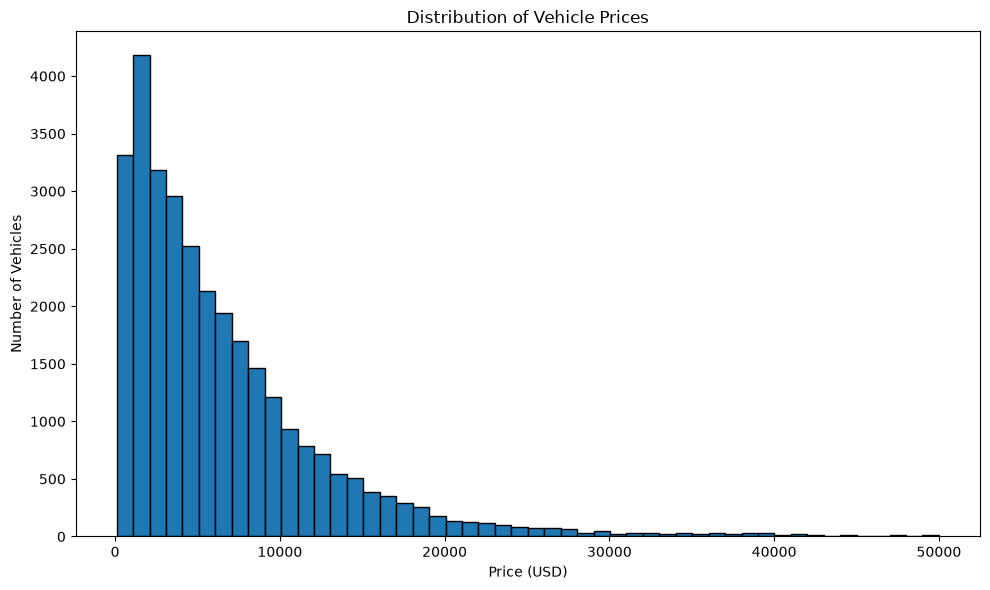

In [14]:
# Visualise the distribution of vehicle prices
plt.figure(figsize=(10, 6))

plt.hist(analysis_df["price_usd"], bins=50, edgecolor="black")

plt.title("Distribution of Vehicle Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Vehicles")

plt.tight_layout()
plt.show()


**Analysis:**

The histogram shows that most vehicles in the dataset are priced between $0 and $10,000. The number of vehicles decreases as the price increases, meaning that higher-priced vehicles are less common.

The distribution is positively skewed (right-skewed), as a smaller number of expensive vehicles extend the distribution towards higher prices.

### 3.2 Relationship Between Vehicle Age and Price

This section investigates the relationship between the year a vehicle was produced and its selling price. A scatter plot is used to identify whether vehicle age has an influence on price.

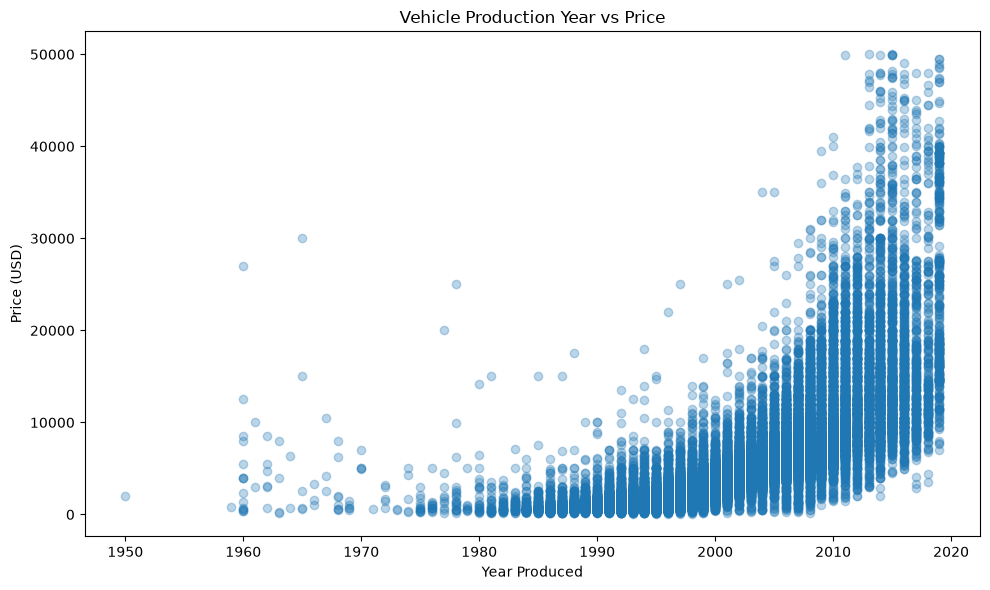

In [16]:
# Relationship between vehicle production year and price
plt.figure(figsize=(10, 6))

plt.scatter(
    analysis_df["year_produced"],
    analysis_df["price_usd"],
    alpha=0.3
)

plt.title("Vehicle Production Year vs Price")
plt.xlabel("Year Produced")
plt.ylabel("Price (USD)")

plt.tight_layout()
plt.show()

**Analysis:**

The scatter plot shows a positive relationship between vehicle production year and selling price. In general, newer vehicles tend to have higher prices than older vehicles.

Prices increase gradually across the earlier production years, with a more noticeable increase around 2010. This suggests that newer vehicles are generally more valuable.

A small number of older vintage vehicles have unusually high prices. However, these are rare exceptions to the overall trend.

Overall, the graph suggests that the year a vehicle was produced is an important factor influencing its selling price.

### 3.3 Relationship Between Mileage and Price

This section investigates the relationship between vehicle mileage and selling price. A scatter plot is used to examine whether vehicles with higher mileage generally have lower prices.

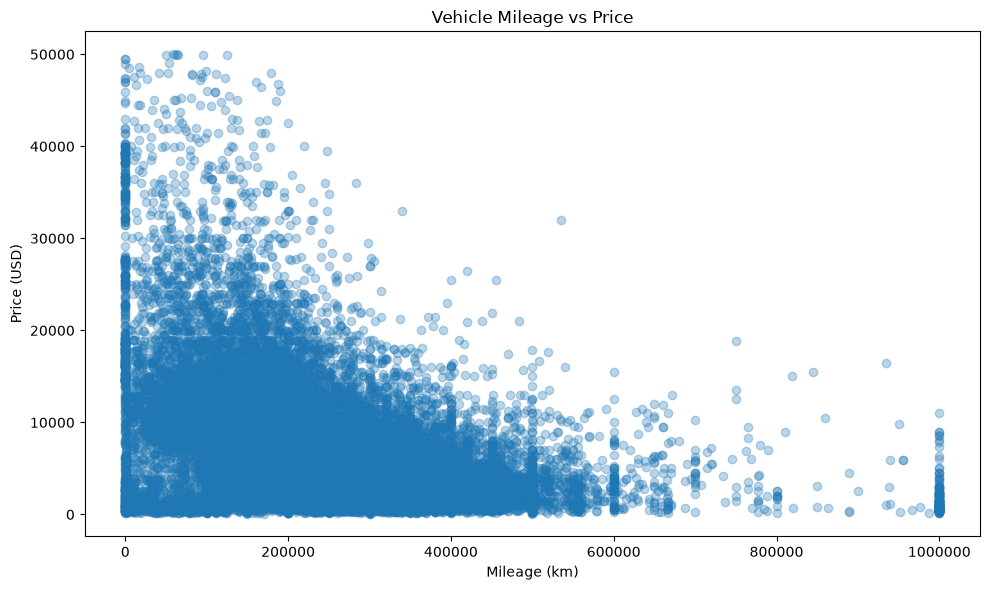

In [20]:
plt.figure(figsize=(10, 6))

plt.scatter(
    analysis_df["odometer_value"],
    analysis_df["price_usd"],
    alpha=0.3
)

plt.title("Vehicle Mileage vs Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (USD)")

# Display mileage in normal numbers instead of scientific notation
plt.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

In [21]:
# Count vehicles with exactly 1,000,000 km
max_mileage_cars = analysis_df[
    analysis_df["odometer_value"] == 1000000
]

print("Vehicles with 1,000,000 km:", len(max_mileage_cars))

Vehicles with 1,000,000 km: 133


In [22]:
# Examine vehicles with the maximum recorded mileage
max_mileage_cars[
    ["manufacturer_name", "model_name", "year_produced",
     "odometer_value", "price_usd"]
].head(20)


,manufacturer_name,model_name,year_produced,odometer_value,price_usd
215,Volkswagen,Golf,1990,1000000,1600.0
1730,Volkswagen,Passat,1995,1000000,2000.0
1891,Ford,Sierra,1987,1000000,430.0
1905,Ford,Galaxy,2003,1000000,6000.0
2026,Ford,Escort,1991,1000000,400.0
2164,Volkswagen,Passat,1991,1000000,1200.0
2423,Kia,Sephia,1994,1000000,200.0
2689,Volkswagen,Passat,1987,1000000,600.0
2922,ВАЗ,2121,1987,1000000,2100.0
3186,Peugeot,308,2008,1000000,5000.0


**Analysis:**

The scatter plot suggests a negative relationship between vehicle mileage and selling price. In general, vehicles with higher mileage tend to have lower prices.

Most vehicles are concentrated at lower mileage values, while vehicles with mileage above 500,000 km are relatively uncommon and generally have lower selling prices.

Some vehicles are recorded at exactly 1,000,000 km. These records may represent unusually high mileage or possible data entry limitations. However, they have been retained because their accuracy cannot be confirmed.

Overall, mileage appears to be another important factor that may influence vehicle selling prices.
    

### 3.4 Average Vehicle Price by Manufacturer

This section examines how average vehicle prices differ between manufacturers. A bar chart is used to compare the average selling prices and identify which manufacturers tend to have more expensive vehicles.

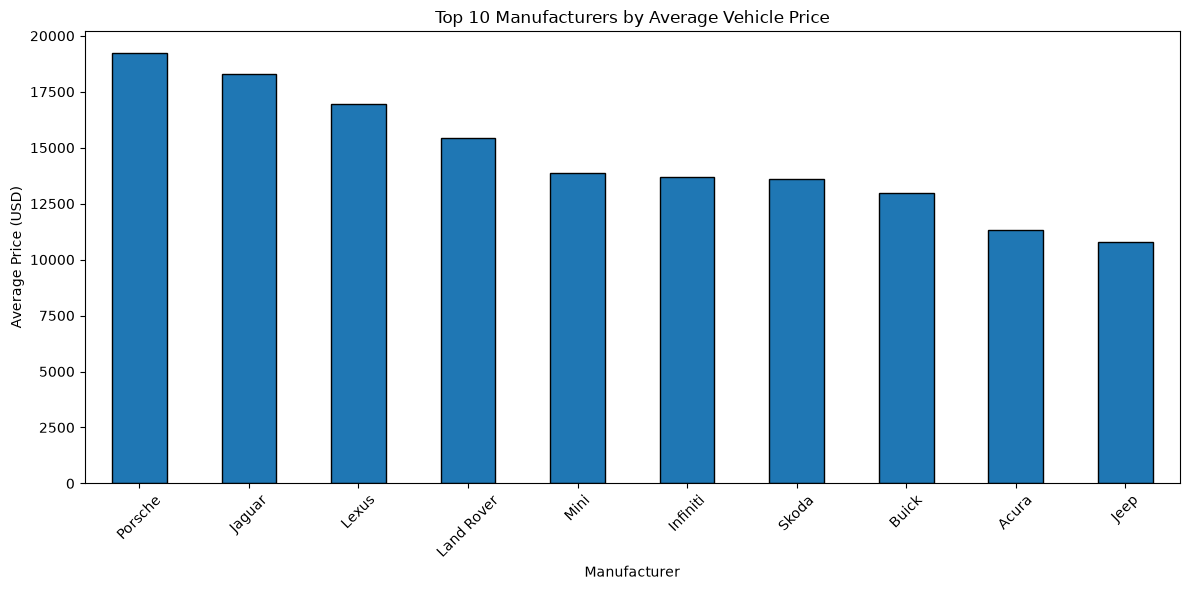

In [25]:
# Calculate average vehicle price for each manufacturer
manufacturer_prices = (
    analysis_df.groupby("manufacturer_name")["price_usd"]
    .mean()
    .sort_values(ascending=False)
)

# Display the 10 manufacturers with the highest average prices
top_manufacturers = manufacturer_prices.head(10)

# Create bar chart
plt.figure(figsize=(12, 6))

top_manufacturers.plot(kind="bar", edgecolor="black")

plt.title("Top 10 Manufacturers by Average Vehicle Price")
plt.xlabel("Manufacturer")
plt.ylabel("Average Price (USD)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Analysis:**

The bar chart shows the 10 manufacturers with the highest average vehicle prices in the dataset.

Porsche has the highest average selling price, followed by Jaguar, Lexus and Land Rover. Other manufacturers appearing in the top 10 include Mini, Infiniti, Skoda, Buick, Acura and Jeep.

The results show that average vehicle prices vary considerably between manufacturers. However, these averages may be influenced by the number of vehicles listed and the models available for each manufacturer.

Overall, manufacturer appears to be another factor that may influence vehicle selling prices.


### 3.5 Correlation Between Numerical Variables

This section examines the relationships between numerical variables in the dataset. A correlation matrix and heatmap are used to identify which variables have the strongest positive or negative relationships with vehicle price.

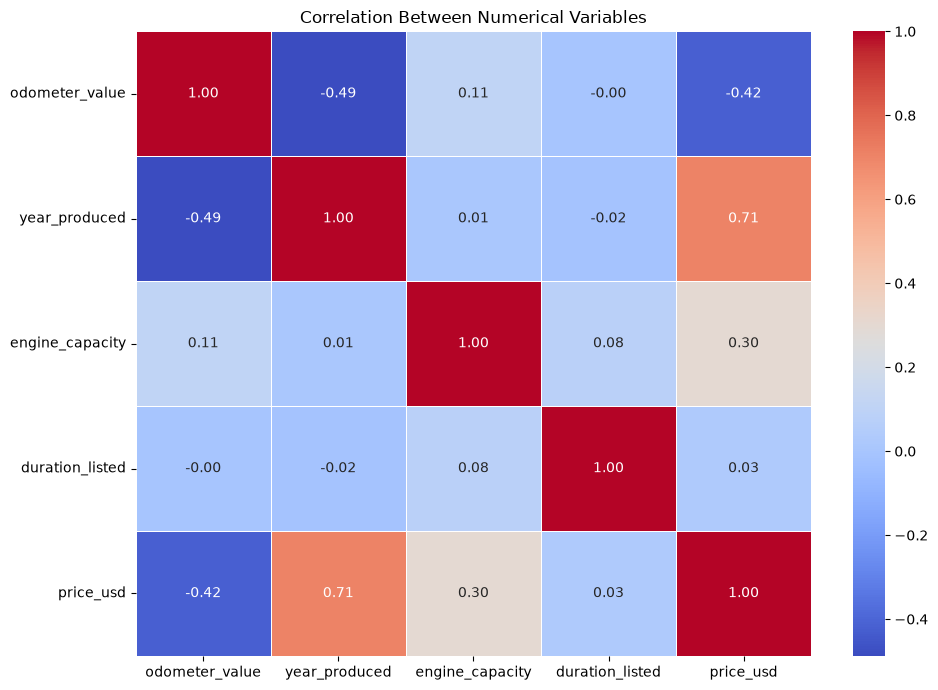

In [27]:
# Select numerical columns
numeric_df = analysis_df.select_dtypes(include=["number"])

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Display correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

The correlation heatmap shows that vehicle production year has the strongest positive correlation with price, with a value of 0.71. This suggests that newer vehicles generally have higher selling prices.

Odometer value has a negative correlation of -0.42, indicating that vehicles with higher mileage tend to have lower prices. Engine capacity has a weaker positive correlation of 0.30, suggesting that vehicles with larger engines may have slightly higher prices.

Duration listed has a correlation of just 0.03, showing almost no linear relationship with vehicle price.

Overall, the results suggest that vehicle age and mileage have the strongest relationships with selling price among the numerical variables examined. However, correlation does not necessarily mean causation.

## 4. Machine Learning – Linear Regression

Linear Regression is a supervised machine learning algorithm used to predict numerical values. In this project, it will be used to predict the selling price of used vehicles based on information such as their production year, mileage, engine capacity and other characteristics.

The dataset will be prepared and divided into training and testing sets before the model is trained and evaluated.

In [28]:
# Select input features
X = analysis_df[
    [
        "year_produced",
        "odometer_value",
        "engine_capacity",
        "manufacturer_name",
        "model_name",
        "engine_fuel",
        "transmission"
    ]
]

# Select target variable
y = analysis_df["price_usd"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (30780, 7)
Target shape: (30780,)


### 4.2 Splitting the Dataset

The dataset is divided into training and testing sets using an 80/20 split. The training data is used to teach the model, while the testing data is used to evaluate its performance on unseen records.

A random state of 42 is used to ensure that the same split can be reproduced.

In [32]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (24624, 7)
Testing features: (6156, 7)
Training targets: (24624,)
Testing targets: (6156,)


### 4.3 Preparing Categorical Features

The dataset contains both numerical and categorical features. Numerical features can be used directly, while categorical features such as manufacturer, model, fuel type and transmission must be converted into numerical representations.

One-Hot Encoding will be used to convert these categorical values into a format that can be processed by the Linear Regression model.

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Use the same seven predictors for both regression and classification.
numeric_features = ["year_produced", "odometer_value", "engine_capacity"]
categorical_features = [
    "manufacturer_name", "model_name", "engine_fuel", "transmission"
]

# Each model fits its own imputer and scaler on its training data only.
numeric_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessing, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)

Numerical features: ['year_produced', 'odometer_value', 'engine_capacity']
Categorical features: ['manufacturer_name', 'model_name', 'engine_fuel', 'transmission']


### 4.4 Training the Linear Regression Model

A Linear Regression model is created and trained using the prepared training dataset. A pipeline is used to combine the preprocessing steps and model training into one process.

The model learns relationships between the vehicle characteristics and their selling prices, allowing it to make predictions on unseen vehicle records.

In [35]:
from sklearn.linear_model import LinearRegression

# Create the machine learning pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


### 4.5 Evaluating the Linear Regression Model

The trained model is evaluated using the testing dataset, which contains vehicles that were not used during training.

Three evaluation metrics are used: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and the R² score. These metrics help measure the accuracy of the model and how well it predicts vehicle selling prices.

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate predictions using the testing data
y_pred = linear_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): $1740.95
Root Mean Squared Error (RMSE): $2872.18
R² Score: 0.7972


### 4.6 Comparing Actual and Predicted Prices

A scatter plot is used to compare the actual vehicle prices with the prices predicted by the Linear Regression model. The closer the points are to the diagonal reference line, the more accurate the predictions are.

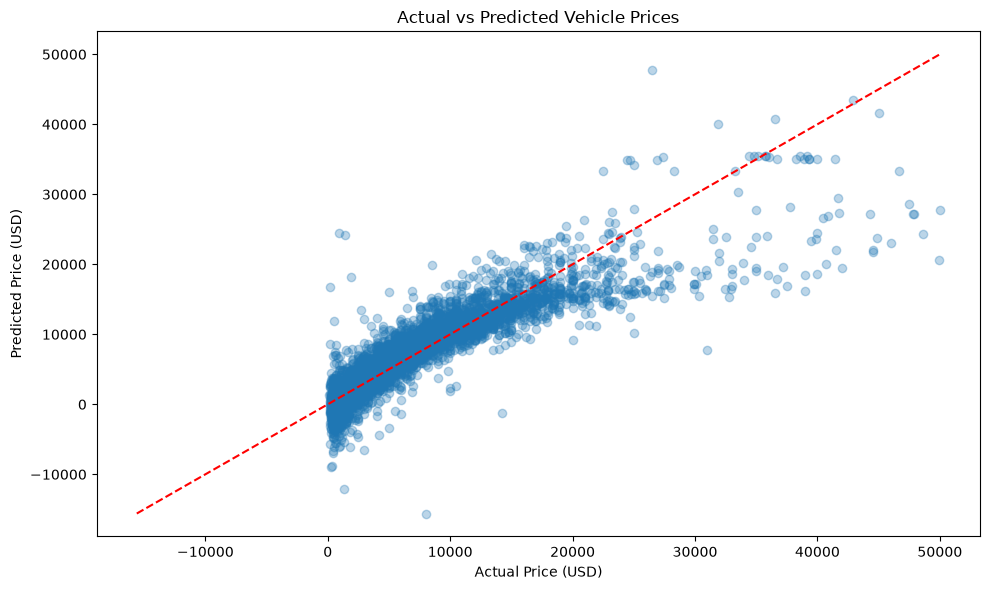

In [37]:
# Compare actual prices with predicted prices
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

# Add a reference line for perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--"
)

plt.title("Actual vs Predicted Vehicle Prices")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.tight_layout()
plt.show()

The scatter plot shows that the model generally predicts vehicle prices more accurately for vehicles priced between $0 and $20,000, as most points are relatively close to the reference line.

For vehicles priced above $20,000, the predictions become more scattered and many points appear below the reference line. This suggests that the model tends to underestimate some higher-priced vehicles.

Overall, the model performs reasonably well for the majority of vehicles but is less accurate when predicting the prices of more expensive vehicles. This may be because higher-priced vehicles have additional characteristics that are not fully captured by the selected features.

## 5. Random Forest Regression

Random Forest Regression is a supervised machine learning algorithm that combines multiple decision trees to make predictions. Each tree produces a prediction, and the results are combined to generate the final output.

This model will be trained using the same training dataset as the Linear Regression model. Its performance will then be compared against the previous model to determine which algorithm predicts vehicle prices more accurately.

In [39]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### 5.2 Evaluating the Random Forest Model

The Random Forest model is evaluated using the same testing dataset as the Linear Regression model. Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and the R² score are calculated to measure its predictive performance.

In [40]:
# Generate predictions
rf_predictions = random_forest_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Evaluation Results")
print("--------------------------------")
print(f"Mean Absolute Error (MAE): ${rf_mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rf_rmse:.2f}")
print(f"R² Score: {rf_r2:.4f}")

Random Forest Evaluation Results
--------------------------------
Mean Absolute Error (MAE): $1154.20
Root Mean Squared Error (RMSE): $2033.68
R² Score: 0.8983


### 5.3 Comparing regression model performance

Both regressors use the same 80/20 train/test partition and the same predictor variables. The table below compares **MAE** (average absolute price error in dollars), **RMSE** (which penalises large errors more) and **R²** (fraction of test-set price variation accounted for relative to predicting the test-set mean). Lower MAE and RMSE and higher R² are preferable. Random Forest performs better on this split, though results should not be interpreted as a guarantee of performance on a different market or period. The metrics are calculated from the notebook run, rather than copied into this paragraph.

In [42]:
# Compare both machine learning models
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R² Score": [r2, rf_r2]
})

model_comparison

,Model,MAE,RMSE,R² Score
0,Linear Regression,1740.952370,2872.179804,0.797244
1,Random Forest,1154.200091,2033.675355,0.898349


### 5.4 Visual Comparison of Model Performance

A bar chart is used to compare the R² scores of the Linear Regression and Random Forest models. This provides a visual representation of how well each model explains the variation in vehicle selling prices.

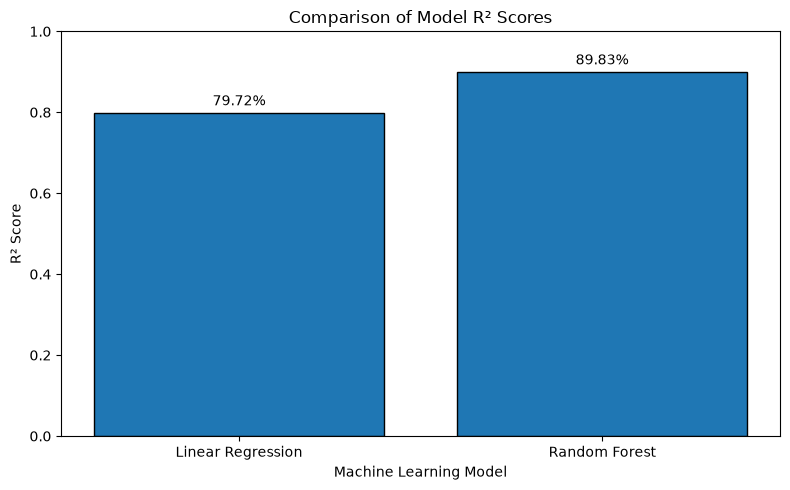

In [44]:
# Compare model R² scores
models = ["Linear Regression", "Random Forest"]
scores = [r2, rf_r2]

plt.figure(figsize=(8, 5))
plt.bar(models, scores, edgecolor="black")

plt.title("Comparison of Model R² Scores")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)

for i, score in enumerate(scores):
    plt.text(i, score + 0.02, f"{score:.2%}", ha="center")

plt.tight_layout()
plt.show()

## 6. Logistic Regression — Classifying Vehicle Prices

**Research question 3:** Can the seven vehicle characteristics used above predict whether a listing price is below **$15,000** (class `0`) or **$15,000 and above** (class `1`)?

Logistic Regression is **supervised classification**, despite its name: it models the estimated probability of the positive class. **$15,000 is a deliberately chosen experimental threshold**, not an official boundary for an expensive vehicle. Because most listings cost less than $15,000, accuracy must be considered alongside minority-class precision, recall, F1, balanced accuracy and ROC AUC. No price information is provided as a predictor.

In [ ]:
# Define the binary target without including price as an input feature.
classification_df = analysis_df.copy()
classification_df["price_category"] = (
    classification_df["price_usd"] >= 15000
).astype(int)

class_counts = classification_df["price_category"].value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Category": ["0: Below $15,000", "1: At least $15,000"],
    "Listings": class_counts.reindex([0, 1], fill_value=0).values,
    "Share (%)": (class_counts.reindex([0, 1], fill_value=0)
                  / len(classification_df) * 100).round(2).values
})
print(class_distribution.to_string(index=False))

### 6.1 Stratified train/test split and preprocessing

As in the regression task, use 80% for training and 20% for testing, with `random_state=42`. The `stratify` argument preserves the approximate class proportions in each partition. A pipeline handles numeric median imputation, numeric scaling and one-hot encoding of text categories. These transformations are fitted only on the training data, protecting the held-out evaluation.

In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

X_classification = classification_df[numeric_features + categorical_features]
y_classification = classification_df["price_category"]

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_classification,
    y_classification,
    test_size=0.2,
    random_state=42,
    stratify=y_classification
)

logistic_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

logistic_model.fit(X_class_train, y_class_train)
print("Logistic Regression model trained.")
print("Training rows:", len(X_class_train))
print("Testing rows:", len(X_class_test))

### 6.2 Evaluate classification results

A model that always predicts the majority (lower-priced) class can achieve a misleadingly high accuracy. Along with accuracy, report **balanced accuracy**, **precision**, **recall**, and **F1-score** for class `1`, plus **ROC AUC** (which considers ranking over all classification probability thresholds). A confusion matrix displays true/false predictions for both classes.

In [ ]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

class_predictions = logistic_model.predict(X_class_test)
class_probabilities = logistic_model.predict_proba(X_class_test)[:, 1]

classification_scores = {
    "Majority-class baseline accuracy": max(y_class_test.mean(), 1 - y_class_test.mean()),
    "Logistic accuracy": accuracy_score(y_class_test, class_predictions),
    "Balanced accuracy": balanced_accuracy_score(y_class_test, class_predictions),
    "Precision (class 1)": precision_score(y_class_test, class_predictions, zero_division=0),
    "Recall (class 1)": recall_score(y_class_test, class_predictions, zero_division=0),
    "F1 (class 1)": f1_score(y_class_test, class_predictions, zero_division=0),
    "ROC AUC": roc_auc_score(y_class_test, class_probabilities)
}
print(pd.Series(classification_scores).round(4).to_string())
print("\nClassification report:\n")
print(classification_report(
    y_class_test, class_predictions,
    target_names=["Below $15,000", "At least $15,000"],
    zero_division=0
))

In [ ]:
# Confusion matrix: rows are actual categories; columns are predictions.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_class_test, class_predictions, display_labels=["Below $15k", "$15k+"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Logistic Regression — Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_class_test, class_probabilities, ax=axes[1],
    name="Logistic Regression"
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
axes[1].set_title("ROC Curve — Higher-price Category")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

### 6.3 Interpretation and limitations

**Observed result on this train/test split:** **97.08% accuracy** compared with **91.02%** if every vehicle were simply predicted to be below $15,000. However, only **8.98%** of listings are in class `1`, so overall accuracy does not tell the full story. Class-1 precision is approximately **0.849**, recall **0.821**, F1 **0.835**, balanced accuracy **0.903** and ROC AUC **0.988**. These indicate useful discrimination on this held-out sample, while also showing that some genuinely higher-priced vehicles are missed.

In the confusion matrix, a **false negative** is a genuinely $15,000+ vehicle predicted to be below $15,000; a **false positive** is the reverse. Precision measures how often predicted higher-priced listings really belong to class `1`, while recall measures the proportion of actual class-`1` listings identified. With the default probability threshold, the model identifies about **82%** of the higher-priced listings in the test set.

**Important distinction:** The prediction *probability* cutoff of 0.5 is not the same as the **$15,000 price boundary** used to create the class labels. The latter is an intentionally simple research threshold, not an official market category. Logistic Regression predicts a price *band*, not an exact dollar price. Results can change with a different test split, dataset, class boundary or decision threshold. Re-run cells to regenerate the exact metrics for the installed scikit-learn version.

## 7. K-Means Clustering — Finding Similar Vehicle Groups

**Research question 4:** Can the vehicles be grouped based on **production year, mileage and engine capacity**, without supplying predefined categories?

K-Means is an **unsupervised** algorithm. It assigns each record to the nearest cluster centre in feature space, reducing the within-cluster sum of squared distances (inertia). We standardise the three numeric inputs because mileage is numerically much larger than engine capacity. Missing engine capacities are imputed with the median. **Price is deliberately excluded from the clustering inputs** so that any difference in price across groups can be examined afterwards, rather than built into the clusters.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ["year_produced", "odometer_value", "engine_capacity"]
cluster_preparation = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cluster_matrix = cluster_preparation.fit_transform(analysis_df[cluster_features])
print("Rows and clustering features:", cluster_matrix.shape)

### 7.1 Choosing a number of clusters

Test **k = 2 through 6**. The **silhouette score** measures how well each item fits its own group compared with the nearest alternative group: higher values generally indicate more distinct clusters. To keep this reproducible and computationally manageable, calculate each silhouette score on a random sample of 1,500 rows (using `random_state=42`). Also inspect inertia: inertia usually falls as k rises, so the lowest inertia alone is not a valid selection rule. This exercise uses the highest sampled silhouette score among the five tested values, not a claim that the true number of groups is known.

In [ ]:
cluster_results = []
for k in range(2, 7):
    candidate_model = KMeans(n_clusters=k, n_init=10, random_state=42)
    candidate_labels = candidate_model.fit_predict(cluster_matrix)
    cluster_results.append({
        "k": k,
        "Silhouette (1,500-row sample)": silhouette_score(
            cluster_matrix, candidate_labels,
            sample_size=1500, random_state=42
        ),
        "Inertia": candidate_model.inertia_
    })

cluster_comparison = pd.DataFrame(cluster_results)
best_k = int(cluster_comparison.loc[
    cluster_comparison["Silhouette (1,500-row sample)"].idxmax(), "k"
])
print(cluster_comparison.round(3).to_string(index=False))
print("\nBest k within the tested range:", best_k)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cluster_comparison["k"],
             cluster_comparison["Silhouette (1,500-row sample)"], "o-")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Sample silhouette score")
axes[0].set_title("Cluster separation (higher is better)")

axes[1].plot(cluster_comparison["k"], cluster_comparison["Inertia"], "o-")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Inertia")
axes[1].set_title("Within-cluster sum of squares")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 7.2 Fit K-Means and interpret group profiles

Fit the selected `k` using the same standardised three-feature matrix. Then compare group sizes and typical characteristics. The **median listed price is shown only for interpretation** and was not used to form clusters. Cluster numbers (`0`, `1`, ...) are arbitrary labels, not rankings or named market segments.

In [ ]:
kmeans_model = KMeans(n_clusters=best_k, n_init=10, random_state=42)
clustered_df = analysis_df.copy()
clustered_df["cluster"] = kmeans_model.fit_predict(cluster_matrix)

cluster_profile = clustered_df.groupby("cluster").agg(
    Vehicles=("cluster", "size"),
    Mean_year=("year_produced", "mean"),
    Median_km=("odometer_value", "median"),
    Median_engine_litres=("engine_capacity", "median"),
    Median_price_usd=("price_usd", "median")
).round(1)

print("Profiles of the", best_k, "groups:")
print(cluster_profile.to_string())
print("\nShare of dataset in each group (%):")
print((clustered_df["cluster"].value_counts(normalize=True).sort_index() * 100)
      .round(1).to_string())

In [ ]:
# Two-dimensional view of three-dimensional clustering; the engine-size
# dimension still affects the K-Means groups but cannot be shown on these axes.
plot_sample = clustered_df.sample(
    n=min(4000, len(clustered_df)), random_state=42
)
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    plot_sample["year_produced"], plot_sample["odometer_value"],
    c=plot_sample["cluster"], cmap="tab10", alpha=0.35, s=15
)
plt.colorbar(scatter, label="Assigned cluster")
plt.title("K-Means Groups by Production Year and Mileage")
plt.xlabel("Year produced")
plt.ylabel("Mileage (km)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### 7.3 Interpretation and limitations

The tested silhouette scores favour **three clusters** (approximately **0.384** for k = 3, compared with **0.345** for k = 2 and lower sampled scores for k = 4–6). This suggests a moderately separated grouping within the selected range; it does not establish that exactly three natural vehicle classes exist.

The fitted profiles are informative:

- **Cluster 0 (~11%):** average production year around **2006**, median mileage **230,000 km**, median engine **3.3 L**, and median listed price **$10,000**. It generally contains larger-engine vehicles.
- **Cluster 1 (~37%):** average production year around **2010**, median mileage **150,000 km**, median engine **1.6 L**, and median price **$8,500**. These cars are newer and typically lower-mileage.
- **Cluster 2 (~52%):** average production year around **1997**, median mileage about **311,000 km**, median engine **2.0 L**, and median price **$2,455**. These tend to be older, higher-mileage listings.

The cluster numbers are **arbitrary**, not price rankings. Listed price was **not included** when creating the clusters, so price differences are a secondary observation. K-Means depends on numeric features, scaling, outliers and the chosen k; manufacturer, model and transmission were not used. A two-axis plot also cannot display the engine-capacity dimension, so overlapping colours on the plot do not necessarily indicate an error in the three-dimensional grouping.

## 8. Overall Conclusions

This portfolio answers four related questions about the advertised prices and characteristics of used cars.

1. **Exploratory analysis:** Production year has a positive association with listed price, while mileage tends to have a negative association. Correlations and visualisations describe patterns, not causes.
2. **Predicting exact prices:** On the held-out test set, **Linear Regression** achieved R² of approximately **0.797** and MAE of about **$1,741**; **Random Forest Regression** improved these to R² of about **0.898** and MAE of about **$1,154**. It also achieved lower RMSE, making it the better regressor in this comparison.
3. **Classifying the $15,000 price band:** Logistic Regression achieved approximately **97.1% accuracy**, **0.835 F1** for the less-common $15,000+ class and **0.988 ROC AUC**. The majority-class baseline was already **91.0% accurate**, reinforcing the need to examine minority-class recall and precision rather than accuracy alone.
4. **Discovering similar cars:** With year, mileage and engine capacity as the only inputs, K-Means selected **three clusters** from k = 2–6 on the sampled silhouette criterion. The groups differ in age, mileage and engine size and also show different median listed prices when examined afterwards.

**Limitations:** Supervised results come from a single train/test split and may not transfer to other countries, later listings or new data sources. The dataset contains extreme values, while its exact sampling method and timeframe are not established. Filtering records below $100, imputing missing engine capacities and choosing a $15,000 classification boundary are analysis decisions that influence results. The K-Means cluster number is exploratory and is not a validated industry segmentation.

**Further work:** Cross-validation, more features and error analysis for high-priced cars could improve evaluation. Model hyperparameters could be tuned using training data alone, and alternative clustering algorithms could be compared. None of the models should be used as an authoritative valuation service.

*Metric values are from a reproducible execution using `random_state=42`; regenerate the outputs before final submission, as small changes can occur across library versions or environments.*

## 9. Reproducibility, Sources and Professional Practice

The notebook uses **`random_state=42`** for repeatable splitting, training and sampling. Regression/classification preprocessing is fitted on the **training** subset through scikit-learn pipelines; the test set is reserved for evaluation. Clustering is unsupervised and uses its own preprocessing over the unlabeled feature matrix.

**Project files:** `Automobile_Price_Analysis.ipynb`, `public_cars.csv`, `requirements.txt`, `README.md`, and `WORK_DIARY_TEMPLATE.md`. The work diary must be populated with **real, dated work** before submission; no dates or activities have been invented.

### References

- **Dataset:** `public_cars.csv` (local supplied dataset, 30,824 rows). A publicly listed dataset with a matching schema is [Used Cars Price (Kaggle)](https://www.kaggle.com/datasets/sivaakhilnukala/used-cars-price). **Verify that this is the actual source used to obtain the file before asserting dataset provenance in the final submission.**
- pandas documentation: https://pandas.pydata.org/docs/
- NumPy documentation: https://numpy.org/doc/stable/
- Matplotlib documentation: https://matplotlib.org/stable/
- seaborn documentation: https://seaborn.pydata.org/
- scikit-learn user guide, supervised learning: https://scikit-learn.org/stable/supervised_learning.html
- scikit-learn user guide, clustering: https://scikit-learn.org/stable/modules/clustering.html
- scikit-learn documentation, preprocessing and pipelines: https://scikit-learn.org/stable/modules/compose.html

**Academic presentation:** The final presentation should explain the research questions, data cleaning, why the three supervised models have different targets/outputs, why the Logistic Regression classes are imbalanced, how k was selected, and the limitations above. All results should be regenerated by running all cells before submission.